# Exercise Session 4: Prognostics for Turbofine Engines 🩺

Prognostics is the prediction of Remaining useful life of instance of failure of a component based on the knowledge about current and future coditions of operation (obtained through various sensors or physical models).

The new C-MAPSS dataset DS02 from NASA provides degradation trajectories of 9 turbofan engines with unknown and different initial health condition for complete flights and two failure modes (HPT efficiency degradation & HPT efficiency degradation combined with LPT efficiency and capacity degradation). The data were synthetically generated with the Commercial Modular Aero-Propulsion System Simulation (C-MAPSS) dynamical model. The data contains multivariate sensors readings of the complete run-to-failure trajectories. Therefore, the records stop at the cycle/time the engine failed. A total number of 6.5M time stamps are available. Dataset copyright (c) by Manuel Arias.

**For training simplicity, the dataset has been preprocessed. The dataset has been downsampled from 1Hz to 0.1 Hz with an IIR 8th Order Chebyshev filter. Data format has been converted from double to float precison.**

## Imports 💼

In [5]:
import os
import time
import random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, SubsetRandomSampler
from sklearn.preprocessing import MinMaxScaler

%matplotlib inline

## Download dataset 🔗

In [2]:
!wget --load-cookies /tmp/cookies.txt "https://docs.google.com/uc?export=download&confirm=$(wget --quiet --save-cookies /tmp/cookies.txt --keep-session-cookies --no-check-certificate 'https://docs.google.com/uc?export=download&id=12rINESJozO70X-48pGNiaHfxEpjsROpd' -O- | sed -rn 's/.*confirm=([0-9A-Za-z_]+).*/\1\n/p')&id=12rINESJozO70X-48pGNiaHfxEpjsROpd" -O ncmapps_ds02.csv && rm -rf /tmp/cookies.txt

'wget' is not recognized as an internal or external command,
operable program or batch file.


In [9]:
folder = os.getcwd()
filename = f"{folder}/datasets/ncmapps_ds02.csv"
print(
    filename,
    "File is there, good job"
    if Path(filename).exists()
    else "NO FILE dude, please check again",
)

c:\Users\Raffael\Documents\Workspaces\work\SBB_Lastprognose/datasets/ncmapps_ds02.csv File is there, good job


# Data exploration 🔍

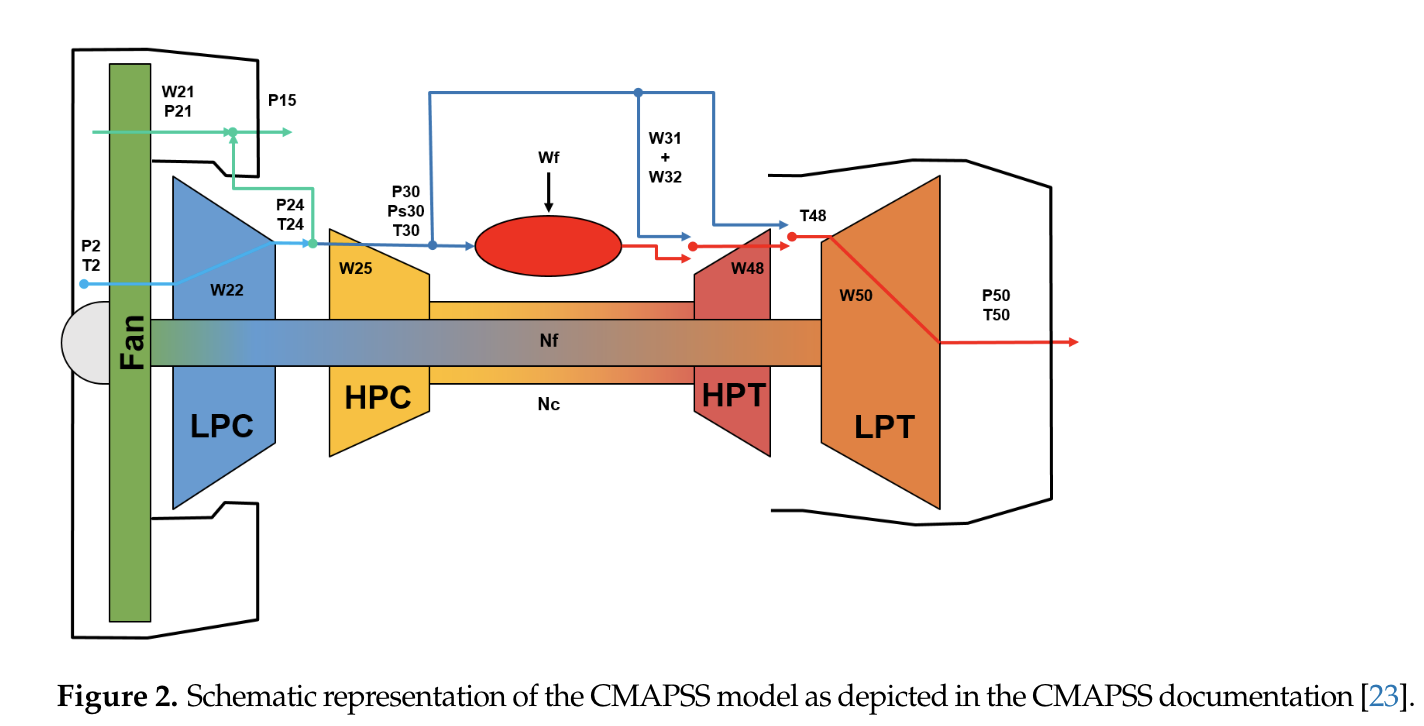

### Feature descriptions

| Symbol |           Description           | Units |
|:------:|:-------------------------------:|:-----:|
|   Wf   |            Fuel flow            |  pps  |
|   Nf   |        Physical fan speed       |  rpm  |
|   Nc   |       Physical core speed       |  rpm  |
|   T24  | Total temperature at LPC outlet |   °R  |
|   T30  | Total temperature at HPC outlet |   °R  |
|   T48  | Total temperature at HPT outlet |   °R  |
|   T50  | Total temperature at LPT outlet |   °R  |
|   P15  |  Total pressure in bypass-duct  |  psia |
|   P2   |   Total pressure at fan inlet   |  psia |
|   P21  |   Total pressure at fan outlet  |  psia |
|   P24  |   Total pressure at LPC outlet  |  psia |
|  Ps30  |  Static pressure at HPC outlet  |  psia |
|   P40  | Total pressure at burner outlet |  psia |
|   P50  |   Total pressure at LPT outlet  |  psia |
|   alt  |             Altitude            |   ft  |
|  Mach  |        Flight Mach number       |   -   |
|   TRA  |     Throttle–resolver angle     |   %   |
|   T2   |  Total temperature at fan inlet |   °R  |
|  cycle |       Flight cycle number       |   -   |
|   Fc   |           Flight class          |   -   |
|   hs   |           Health state          |   -   |

In [10]:
df = pd.read_csv(filename)
df.head()

,T24,T30,T48,T50,P15,P2,P21,P24,Ps30,P40,...,Wf,alt,Mach,TRA,T2,RUL,Fc,unit,hs,cycle
0,593.28656,1422.0460,1797.2323,1214.0819,15.626362,11.445379,15.864327,19.897537,327.51962,332.79700,...,3.811431,9889.289,0.443401,76.022545,496.67758,74,3,2,1,1
1,593.30220,1422.3720,1797.9927,1214.1847,15.607640,11.424822,15.845321,19.881628,327.48330,332.75565,...,3.812693,9951.729,0.444472,76.222015,496.53890,74,3,2,1,1
2,593.14215,1421.8730,1797.1808,1213.5430,15.581609,11.407368,15.818893,19.848164,326.81784,332.08163,...,3.803472,10011.879,0.445830,76.191210,496.43396,74,3,2,1,1
3,592.98883,1421.4746,1796.5925,1213.0120,15.554759,11.387945,15.791634,19.814800,326.22076,331.47592,...,3.795554,10073.271,0.446986,76.196846,496.30667,74,3,2,1,1
4,592.66296,1420.8185,1795.7623,1212.4274,15.512026,11.356153,15.748249,19.760134,325.36660,330.60760,...,3.784542,10136.359,0.446471,76.204480,496.02774,74,3,2,1,1


In [5]:
df.describe()

,T24,T30,T48,T50,P15,P2,P21,P24,Ps30,P40,...,Wf,alt,Mach,TRA,T2,RUL,Fc,unit,hs,cycle
count,651719.000000,651719.000000,651719.000000,651719.000000,651719.000000,651719.000000,651719.000000,651719.000000,651719.000000,651719.000000,...,651719.000000,651719.000000,651719.000000,651719.000000,651719.000000,651719.000000,651719.000000,651719.000000,651719.000000,651719.000000
mean,553.773261,1305.850995,1624.971227,1095.696343,10.873508,8.294637,11.039095,13.643750,208.496462,212.067515,...,2.253705,21119.237345,0.610494,67.194135,470.945280,36.166254,2.885379,11.667088,0.242413,36.923423
std,17.911969,55.450514,98.490373,51.542820,2.151641,1.772237,2.184407,2.623686,44.015363,44.661923,...,0.570109,6289.970530,0.079231,14.527711,16.562547,21.888520,0.386773,6.039347,0.428543,21.871899
min,478.632600,1059.667800,1209.931600,880.090700,5.852047,4.347817,5.941164,6.836902,79.552380,81.277596,...,0.669135,9882.690000,0.307302,19.149189,417.287570,0.000000,1.000000,2.000000,0.000000,1.000000
25%,541.163970,1275.104050,1576.463600,1062.239200,9.047318,6.723060,9.185095,11.490683,177.011890,180.088135,...,1.862427,15698.589500,0.552379,57.695049,457.398350,18.000000,3.000000,5.000000,0.000000,18.000000
50%,551.275940,1304.876100,1634.922400,1087.750400,10.440776,7.942872,10.599772,13.147205,198.354350,201.783000,...,2.120128,21750.955000,0.623288,73.139915,469.305800,35.000000,3.000000,11.000000,0.000000,36.000000
75%,565.815665,1340.213050,1683.188100,1128.510400,12.557189,9.760832,12.748416,15.541450,235.666880,239.740805,...,2.575994,26692.051500,0.673824,78.666230,485.250000,54.000000,3.000000,18.000000,0.000000,54.000000
max,610.117900,1484.438500,1920.566000,1282.403800,16.686320,12.159272,16.940426,21.708801,376.933350,382.565220,...,4.619399,34629.797000,0.738229,91.356170,505.425720,88.000000,3.000000,20.000000,1.000000,89.000000


### Flight Classes

The units are divided into three flight classes depending on whether the unit is operating short-length flights (i.e., flight class 1), medium-length flights (i.e., flight class 2), or long-length flights (i.e., flight class 2). A number of real flight conditions are available within each of the flight classes.

| Flight Class   | Flight Length [h]
| :-----------:  | :-----------:    
| 1              |    1 to 3        
| 2              |    3 to 5        
| 3              |    5 to 7        

<Axes: xlabel='Unit # [-]', ylabel='Flight Class # [-]'>

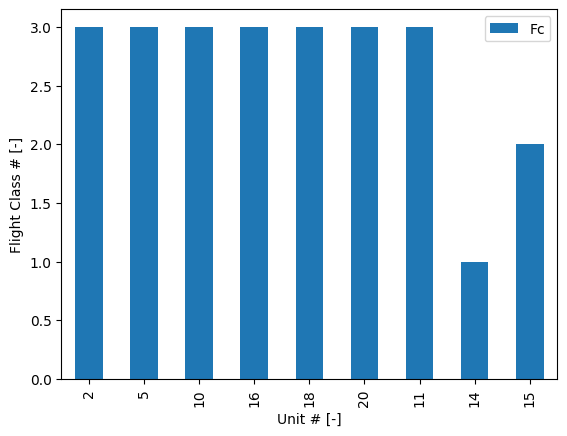

In [11]:
df.drop_duplicates(subset=["unit", "Fc"], keep="last").plot(
    x="unit", y="Fc", kind="bar", xlabel="Unit # [-]", ylabel="Flight Class # [-]"
)

## Feature Overview

In [12]:
LABELS = ["RUL"]

Operative Conditions ($w$)

DASHlink- Flight Data For Tail 687.(2012). Retrieved on 2019-01-29 from https://c3.nasa.gov/dashlink/

In [13]:
W_VAR = ["alt", "Mach", "TRA", "T2"]

Sensor readings ($X_s$)

In [14]:
XS_VAR = [
    "T24",
    "T30",
    "T48",
    "T50",
    "P15",
    "P2",
    "P21",
    "P24",
    "Ps30",
    "P40",
    "P50",
    "Nf",
    "Nc",
    "Wf",
]

<Axes: >

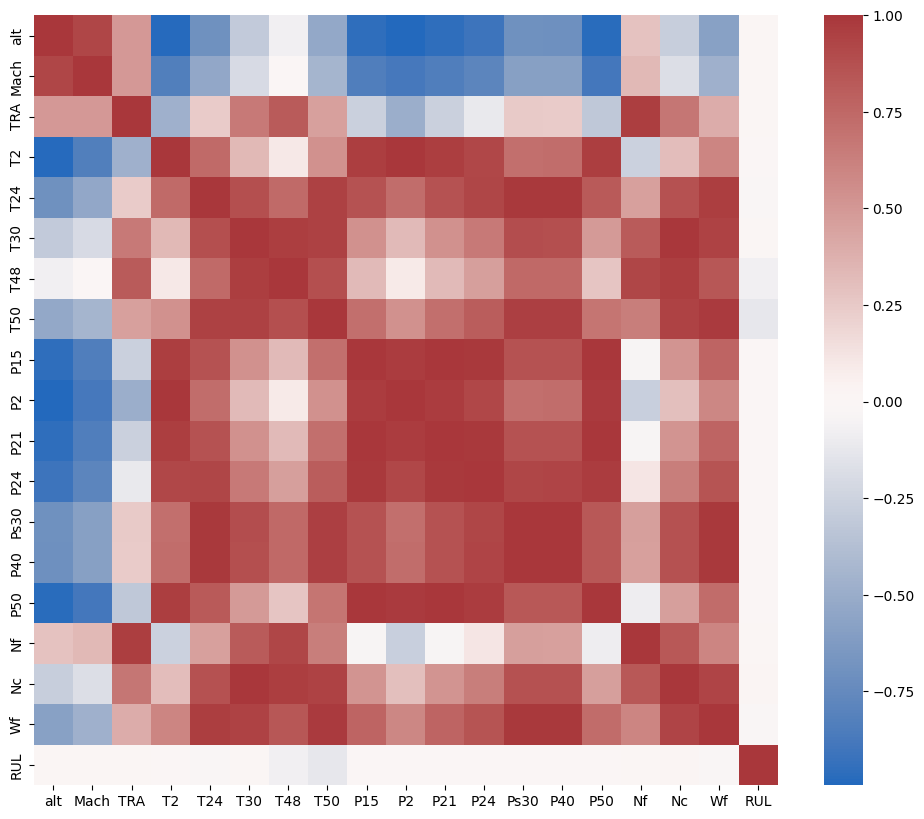

In [15]:
f, ax = plt.subplots(1, 1, figsize=(12, 10))
sns.heatmap(df[W_VAR + XS_VAR + LABELS].corr(), cmap="vlag")

### Flight Traces
visualize a single flight trace of a given unit

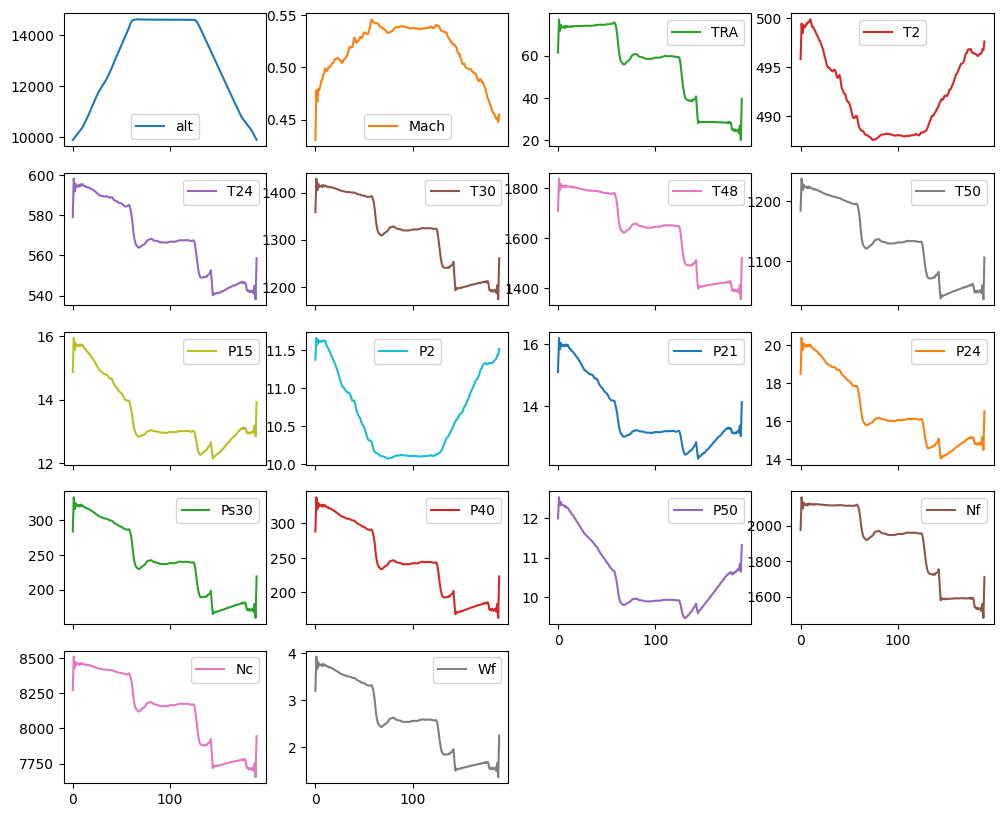

In [16]:
unit = 14
cycle = 70
df_u_sel = df.loc[(df.unit == unit) & (df.cycle == cycle)][W_VAR + XS_VAR]
df_u_sel.reset_index(inplace=True, drop=True)
axes = df_u_sel.plot(figsize=(12, 10), subplots=True, layout=(5, 4))

### Flight envelope

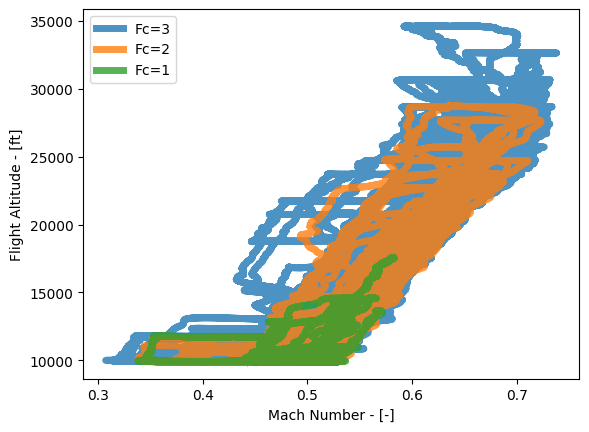

In [17]:
f, ax = plt.subplots(1, 1)
for i in [3, 2, 1]:
    df.loc[df["Fc"] == i].plot(
        x="Mach", y="alt", alpha=0.8, label=f"Fc={i}", ax=ax, lw=5
    )
plt.xlabel("Mach Number - [-]")
plt.ylabel("Flight Altitude - [ft]")
plt.legend()

## Histogram of Flight Conditions

C:\Users\Raffael\AppData\Local\Temp\ipykernel_34100\1009597741.py:3: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data=df[W_VAR+['unit']], x=var, hue='unit', shade=True, gridsize=100, ax=axes[i//2][i%2], palette=sns.color_palette("husl", 9))
C:\Users\Raffael\AppData\Local\Temp\ipykernel_34100\1009597741.py:3: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data=df[W_VAR+['unit']], x=var, hue='unit', shade=True, gridsize=100, ax=axes[i//2][i%2], palette=sns.color_palette("husl", 9))
C:\Users\Raffael\AppData\Local\Temp\ipykernel_34100\1009597741.py:3: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data=df[W_VAR+['unit']], x=

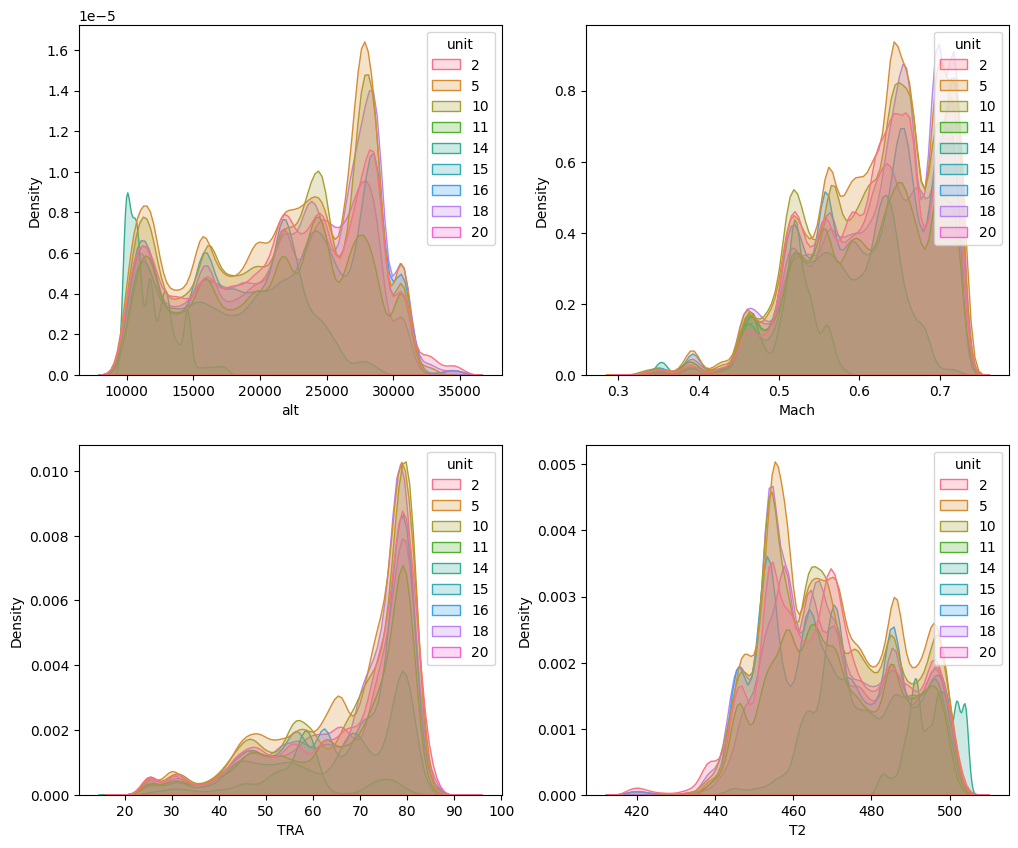

In [18]:
f, axes = plt.subplots(2, 2, figsize=(12, 10))
for i, var in enumerate(W_VAR):
    sns.kdeplot(
        data=df[W_VAR + ["unit"]],
        x=var,
        hue="unit",
        shade=True,
        gridsize=100,
        ax=axes[i // 2][i % 2],
        palette=sns.color_palette("husl", 9),
    )

# Developing your first prognostics model 💻
Step by step, you will learn how to build your first prognostics model from scratch!

## Define Sequence Dataset 


In [19]:
class SlidingWindowDataset(Dataset):
    def __init__(self, dataframe, window=50, stride=1, horizon=1, device="cpu"):
        """Sliding window dataset with RUL label

        Args:
            dataframe (pd.DataFrame): dataframe containing scenario descriptors and sensor reading
            window (int, optional): sequence window length. Defaults to 50.
            stride (int, optional): data stride length. Defaults to 1.
            horizon (int, optional): prediction forcasting length. Defaults to 1.
        """
        self.window = window
        self.stride = stride
        self.horizon = horizon

        self.X = np.array(dataframe[XS_VAR + W_VAR].values).astype(np.float32)
        self.y = np.array(dataframe["RUL"].values).astype(np.float32)
        if "ds" in dataframe.columns:
            unqiue_cycles = dataframe[["ds", "unit", "cycle"]].value_counts(sort=False)
        else:
            unqiue_cycles = dataframe[["unit", "cycle"]].value_counts(sort=False)
        self.indices = torch.from_numpy(self._get_indices(unqiue_cycles)).to(device)

    # TODO add comment
    def _get_indices(self, unqiue_cycles):
        cycles = unqiue_cycles.to_numpy()
        idx_list = []
        for i, c_count in enumerate(cycles):
            c_start = sum(cycles[:i])
            c_end = c_start + (c_count - self.window - self.horizon)
            if c_end + self.horizon < len(
                self.X
            ):  # handling y not in the last seq case
                idx_list += [_ for _ in np.arange(c_start, c_end + 1, self.stride)]
        return np.asarray([(idx, idx + self.window) for idx in idx_list])

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        i_start, i_stop = self.indices[i]
        x = self.X[i_start:i_stop, :]
        y = self.y[i_start]
        return x, y

In [66]:
def create_datasets(df, window_size, train_units, test_units, device="cpu", stride=1):
    df_train = df[df["unit"].isin(train_units)]
    train_dataset = SlidingWindowDataset(df_train, stride=stride, window=window_size)

    df_test = df[df["unit"].isin(test_units)]
    test_dataset = SlidingWindowDataset(df_test, stride=stride, window=window_size)

    # normalizing features
    scaler = MinMaxScaler()
    train_dataset.X = scaler.fit_transform(train_dataset.X)
    test_dataset.X = scaler.transform(test_dataset.X)

    # convert numpy array to tensors
    datasets = [train_dataset, test_dataset]
    for d in datasets:
        d.X = torch.from_numpy(d.X).to(device)
        d.y = torch.from_numpy(d.y).to(device)

    return datasets


def create_data_loaders(datasets, batch_size=256, val_split=0.2):
    d_train, d_test = datasets
    dataset_size = len(d_train)
    indices = list(range(dataset_size))
    split = int(np.floor(val_split * dataset_size))
    np.random.shuffle(indices)
    train_indices, val_indices = indices[split:], indices[:split]
    train_sampler = SubsetRandomSampler(train_indices)
    valid_sampler = SubsetRandomSampler(val_indices)

    train_loader = DataLoader(d_train, batch_size=batch_size, sampler=train_sampler)
    val_loader = DataLoader(d_train, batch_size=batch_size, sampler=valid_sampler)
    test_loader = DataLoader(d_test, batch_size=batch_size, shuffle=False)

    d_info = f"train_size: {len(train_indices)}\t"
    d_info += f"validation_size: {len(val_indices)}\t"
    d_info += f"test_size: {len(d_test)}"
    print(d_info)
    return train_loader, val_loader, test_loader

## Define Trainer Class

In [21]:
class Trainer:
    def __init__(
        self,
        model,
        optimizer,
        n_epochs=20,
        criterion=nn.MSELoss(),
        model_name="best_model",
        device="cpu",
    ):
        self.model = model
        self.optimizer = optimizer
        self.device = device
        self.n_epochs = n_epochs
        self.criterion = criterion

        # adding time_stamp to model name to make sure the save models don't overwrite each other,
        # you can customize your own model name with hyperparameters so that you can reload the model more easily
        time_stamp = time.strftime("%m%d%H%M%S")
        self.model_path = f"models/{model_name}_{time_stamp}.pt"

        self.losses = {split: [] for split in ["train", "eval", "test"]}

    def compute_loss(self, x, y, model=None):
        y = y.view(-1)
        y_pred = self.model(x)
        y_pred = y_pred.view(-1)
        loss = self.criterion(y, y_pred)
        return loss, y_pred, y

    def train_epoch(self, loader):
        self.model.train()
        # batch losses
        b_losses = []
        for x, y in loader:
            # Setting the optimizer gradient to Zero
            self.optimizer.zero_grad()
            x.to(torch.device(self.device))
            y.to(torch.device(self.device))

            loss, pred, target = self.compute_loss(x, y)

            # Backpropagate the training loss
            loss.backward()
            self.optimizer.step()
            b_losses.append(loss.detach().numpy())

        # aggregated losses across batches
        agg_loss = np.sqrt((np.asarray(b_losses) ** 2).mean())
        self.losses["train"].append(agg_loss)
        return agg_loss

    # decorator, equivalent to with torch.no_grad():
    @torch.no_grad()
    def eval_epoch(self, loader, split="eval"):
        self.model.eval()
        # batch losses
        b_losses = []
        for x, y in loader:
            x.to(torch.device(self.device))
            y.to(torch.device(self.device))

            loss, pred, target = self.compute_loss(x, y)

            b_losses.append(loss.detach().numpy())

        # aggregated losses across batches
        agg_loss = np.sqrt((np.asarray(b_losses) ** 2).mean())
        self.losses[split].append(agg_loss)
        return agg_loss

    def fit(self, loaders):
        print(f"Training model for {self.n_epochs} epochs...")
        train_loader, eval_loader, test_loader = loaders
        train_start = time.time()

        start_epoch = 0
        best_eval_loss = np.inf

        for epoch in range(start_epoch, self.n_epochs):
            epoch_start = time.time()

            train_loss = self.train_epoch(train_loader)
            eval_loss = self.eval_epoch(eval_loader, split="eval")
            test_loss = self.eval_epoch(test_loader, split="test")

            if eval_loss < best_eval_loss:
                best_eval_loss = eval_loss
                self.save(self.model, self.model_path)

            s = (
                f"[Epoch {epoch + 1}] "
                f"train_loss = {train_loss:.5f}, "
                f"eval_loss = {eval_loss:.5f}, "
                f"test_loss = {test_loss:.5f}"
            )

            epoch_time = time.time() - epoch_start
            s += f" [{epoch_time:.1f}s]"
            print(s)

        train_time = int(time.time() - train_start)

        print(f"Task done in {train_time}s")

    # decorator, equivalent to with torch.no_grad():
    @torch.no_grad()
    def eval_rul_prediction(self, test_loader):
        print("Evaluating test RUL...")

        ## MASK OUT EVAL and add explanation
        best_model = self.load(self.model)
        best_model.eval()

        preds = []
        trues = []

        for x, y in tqdm(test_loader):
            x = x.to(self.device)
            y = y.to(self.device)

            _, y_pred, y_target = self.compute_loss(x, y)
            preds.append(y_pred.detach().cpu().numpy())
            trues.append(y_target.detach().cpu().numpy())

        preds = np.concatenate(preds, axis=0)
        trues = np.concatenate(trues, axis=0)

        df = pd.DataFrame(
            {"pred": preds, "true": trues, "err": np.sqrt((preds - trues) ** 2)}
        )
        return df

    def save(self, model, model_path=None):
        os.makedirs(f"{folder}/models", exist_ok=True)
        if model_path is None:
            model_path = self.model_path
        torch.save(model.state_dict(), model_path)

    def load(self, model, model_path=None):
        """
        loads the prediction model's parameters
        """
        if model_path is None:
            model_path = self.model_path
        model.load_state_dict(torch.load(model_path, map_location=self.device))
        print(
            f"Model {model.__class__.__name__} saved in {model_path} loaded to {self.device}"
        )
        return model

    def plot_losses(self):
        """
        :param losses: dict with losses
        """
        linestyles = {
            "train": "solid",
            "eval": "dashed",
            "test": "dotted",
        }
        for split, loss in self.losses.items():
            ls = linestyles[split]
            plt.plot(range(1, 1 + len(loss)), loss, label=f"{split} loss", linestyle=ls)
            plt.yscale("log")

        plt.title("Training/Validation Losses")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.legend()
        plt.show()

## Define Model: 1DCNN
Conventional CNN's developed for image tasks learn to extract features from the 2D input data. They are autonomous (require no domain expertise or prior info about the image) and thus can be applied to any image regardless of its dimensions. This is due to the fact that these CNN's go through an image by downsampling the image which we call straddling or windowing.  

Similarly 1D CNN learns to extract features from a time series data, by windowing over the data, considering a set of data observations each time. The benefit of using the CNN for sequence classification is that it can learn from the raw time series data, and in turn do not require domain expertise to engineer relevant features.

In [22]:
def init_weights(m):
    if isinstance(m, nn.BatchNorm1d):
        m.weight.data.fill_(1.0)
        m.bias.data.zero_()
    elif isinstance(m, nn.Conv1d) or isinstance(m, nn.Linear):
        m.weight.data = nn.init.xavier_uniform_(
            m.weight.data, gain=nn.init.calculate_gain("relu")
        )
        if m.bias is not None:
            m.bias.data.zero_()


def Single1DCNNLayer(
    in_channels, out_channels=1, dropout=0.2, kernel_size=10, padding="same"
):
    # mask out batchnorm1d
    layer = [
        nn.Conv1d(in_channels, out_channels, kernel_size, padding=padding),
        nn.BatchNorm1d(out_channels),
    ]
    if dropout > 0.0:
        layer.append(nn.Dropout(dropout))
    layer.append(nn.ReLU())
    return layer


class CNN(nn.Module):
    """
    A 1D-CNN model that is based on the paper "Fusing physics-based and deep learning models for prognostics"
    from Manuel Arias Chao et al. (with batchnorm layers)
    """

    def __init__(
        self,
        in_channels=18,
        out_channels=1,
        window=50,
        n_ch=10,
        n_k=10,
        n_hidden=50,
        n_layers=3,
        dropout=0.0,
        padding="same",
    ):
        """
        Args:
            n_features (int, optional): number of input features. Defaults to 18.
            window (int, optional): sequence length. Defaults to 50.
            n_ch (int, optional): number of channels (filter size). Defaults to 10.
            n_k (int, optional): kernel size. Defaults to 10.
            n_hidden (int, optional): number of hidden neurons for regressor. Defaults to 50.
            n_layers (int, optional): number of convolution layers. Defaults to 5.
        """
        super().__init__()

        layers = []
        for i in range(n_layers):
            dim_in = in_channels if i == 0 else n_ch
            dim_out = n_ch if i != n_layers - 1 else 1
            layers += Single1DCNNLayer(
                dim_in, dim_out, dropout=dropout, kernel_size=n_k, padding=padding
            )

        self.cnn_layers = nn.Sequential(*layers)

        # Regression Output
        post_layers = [nn.Linear(in_features=window, out_features=n_hidden)]
        post_layers += [
            nn.ReLU(),
            nn.Linear(in_features=n_hidden, out_features=out_channels),
        ]
        self.rul_regressor = nn.Sequential(*post_layers)
        # Recursive apply weight initialization for all models
        self.apply(init_weights)

    def forward(self, x):
        # Change input shape from (b, window_size, in_channels) to (b, in_channels, window_size)
        x = x.permute(0, 2, 1)

        # Propagate input through Conv-Layers
        feature = self.cnn_layers(x)

        # Flatten the Feature Map
        feature = torch.flatten(feature, start_dim=1)
        output = self.rul_regressor(feature)

        return output

## Training a model instance

In [23]:
def seed_everything(seed: int):
    r"""Sets the seed for generating random numbers in PyTorch, numpy and
    Python.

    Args:
        seed (int): The desired seed.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

In [24]:
# dataset parameters
train_units = [16, 18, 20]
test_units = [2, 11, 14]
window_size = 50

# training parameters
batch_size = 256
base_lr = 1e-3
weight_decay = 1e-5
max_epochs = 10

# CNN model parameters
in_channels = 18
out_channels = 1
n_ch = 10
n_k = 9
n_hidden = 50
n_layers = 3
dropout = 0.0

In [25]:
SEED = 271828  # choose your magic number
seed_everything(SEED)

In [67]:
datasets = create_datasets(
    df, window_size=1, train_units=train_units, test_units=test_units, stride=100
)
loaders = create_data_loaders(datasets, batch_size=batch_size, val_split=0.0)

model = CNN(
    in_channels=in_channels,
    out_channels=out_channels,
    n_ch=n_ch,
    n_k=n_k,
    n_hidden=n_hidden,
    n_layers=n_layers,
    dropout=dropout,
)
print(model)

optimizer = torch.optim.Adam(model.parameters(), lr=base_lr, weight_decay=weight_decay)

criterion = nn.MSELoss()

train_size: 2518	validation_size: 0	test_size: 1760
CNN(
  (cnn_layers): Sequential(
    (0): Conv1d(18, 10, kernel_size=(9,), stride=(1,), padding=same)
    (1): BatchNorm1d(10, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv1d(10, 10, kernel_size=(9,), stride=(1,), padding=same)
    (4): BatchNorm1d(10, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): Conv1d(10, 1, kernel_size=(9,), stride=(1,), padding=same)
    (7): BatchNorm1d(1, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU()
  )
  (rul_regressor): Sequential(
    (0): Linear(in_features=50, out_features=50, bias=True)
    (1): ReLU()
    (2): Linear(in_features=50, out_features=1, bias=True)
  )
)


In [62]:
def dl_to_sklearn_tabpfn(dl):
    X, Y = [], []
    for batch in iter(dl):
        x, y = batch
        X.append(x.squeeze(1))
        Y.append(y.unsqueeze(1))

    return torch.concat(X).numpy(), torch.concat(Y).numpy()

In [72]:
X_train.shape, y_train.shape

((2518, 18), (2518, 1))

In [59]:
X_test.shape, y_test.shape

((1000, 18), (1000, 18))

In [74]:
from sklearn.metrics import mean_squared_error, r2_score
from tabpfn import TabPFNRegressor

batch = next(iter(loaders[0]))
x, y = batch
x.shape, y.shape
N_samples = None


X_train, y_train = dl_to_sklearn_tabpfn(loaders[0])
X_test, y_test = dl_to_sklearn_tabpfn(loaders[2])

if N_samples is not None:
    X_train, y_train = X_train[-N_samples:], y_train[-N_samples:]
    X_test, y_test = X_test[:N_samples], y_test[:N_samples]

# Initialize the regressor
regressor = TabPFNRegressor(ignore_pretraining_limits=True)
regressor.fit(X_train, y_train)

# Predict on the test set
y_test_hat = regressor.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_test_hat)
r2 = r2_score(y_test, y_test_hat)

print("Mean Squared Error (MSE):", np.sqrt(mse))
print("R² Score:", r2)

c:\Users\Raffael\miniforge3\envs\torch2_cuda12.1\lib\site-packages\sklearn\utils\validation.py:1300: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
c:\Users\Raffael\miniforge3\envs\torch2_cuda12.1\lib\site-packages\tabpfn\model\multi_head_attention.py:710: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:252.)
  attention_head_outputs = torch.nn.functional.scaled_dot_product_attention(
c:\Users\Raffael\miniforge3\envs\torch2_cuda12.1\lib\site-packages\tabpfn\model\multi_head_attention.py:710: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:252.)
  attention_head_outputs = torch.nn.functional.scaled_dot_produ

Mean Squared Error (MSE): 5.516364
R² Score: 0.9275321744205184


In [ ]:
def add_unit_to_df(df, units):
    swtich_indicies = [
        i for i, c in enumerate(zip(df.true, df.true[1:])) if c[0] != c[1]
    ]
    eol_indicies = [
        i for i in swtich_indicies if np.isclose(df.true[i], 0.0, rtol=1e-03)
    ]
    df.loc[: eol_indicies[0], "units"] = units[0]
    for i in range(len(eol_indicies) - 1):
        df.loc[eol_indicies[i] : eol_indicies[i + 1], "units"] = units[i + 1]
    df.loc[eol_indicies[-1] :, "units"] = units[-1]
    return df


precision = 5


def agg_runs_by_unit(
    result_dir, scale_y=1, units=[2, 5, 10, 11, 14, 15], verbose=False
):
    df_rmse = pd.DataFrame({k: [] for k in units})
    df_mae = pd.DataFrame({k: [] for k in units})
    df_nasa = pd.DataFrame({k: [] for k in units})
    for run in os.listdir(result_dir):
        if run != "config.yaml":
            result_path = f"{result_dir}/{run}/rul/test.csv"
            df_test = pd.read_csv(result_path, index_col=0)
            df_test *= scale_y
            df_test = add_unit_to_df(df_test, units)
            df_grouped = df_test.groupby(["units"]).mean()
            df_grouped_metric = df_grouped.groupby("units").apply(
                lambda y: pd.Series(
                    {
                        "rmse": np.sqrt(np.mean((y.pred - y.true) ** 2)),
                        "mae": np.mean(abs(y.pred - y.true)),
                        # 'nasa': nasa_score(y.pred, y.true)
                    }
                )
            )
            df_rmse.loc[run] = df_grouped_metric.rmse
            df_mae.loc[run] = df_grouped_metric.mae
            df_nasa.loc[run] = df_grouped_metric.nasa
            # print(f"Run {run} with RMSE {df_test.err.mean():.{precision}f}")
    if verbose:
        unit_str = "Unit:\t"
        rmse_str = "RMSE:\t"
        mae_str = "MAE :\t"
        # nasa_str = 'NASA:\t'
        for unit, err in df_rmse.items():
            unit_str += f" unit {unit} \t "
            rmse_str += f"{err.mean():.{precision}f} ± {err.std():.{precision}f}\t"
            # print(f'RMSE unit {unit}: \t {err.mean():.{precision}f} ± {err.std():.{precision}f}')
        for unit, err in df_mae.items():
            mae_str += f"{err.mean():.{precision}f} ± {err.std():.{precision}f}\t"
        # for unit, err in df_nasa.items():
        #     nasa_str += f'{err.mean():.{precision}f} ± {err.std():.{precision}f}\t'
        print(unit_str)
        print(rmse_str)
        print(mae_str)
        # print(nasa_str)
        print("==================================")
    print(
        f"Overall RMSE: \t {df_rmse.mean().mean():.{precision}f} ± {df_rmse.std().mean():.{precision}f}"
    )
    print(
        f"Overall MAE: \t {df_mae.mean().mean():.{precision}f} ± {df_mae.std().mean():.{precision}f}"
    )
    print(
        f"Overall NASA: \t {df_nasa.mean().mean():.{precision}f} ± {df_nasa.std().mean():.{precision}f}"
    )


def agg_runs_by_cycle(
    result_dir, scale_y=1, units=[2, 5, 10, 11, 14, 15], verbose=False
):
    df_rmse = pd.DataFrame({k: [] for k in units})
    df_mae = pd.DataFrame({k: [] for k in units})
    df_nasa = pd.DataFrame({k: [] for k in units})
    for run in os.listdir(result_dir):
        if run != "config.yaml":
            result_path = f"{result_dir}/{run}/rul/test.csv"
            df_test = pd.read_csv(result_path, index_col=0)
            df_test *= scale_y
            df_test = add_unit_to_df(df_test, units)
            df_grouped = df_test.groupby(["units", "true"]).mean()
            df_grouped = df_test.groupby(["units", "true"], sort=False).mean()
            df_grouped = df_grouped.reset_index()
            df_grouped_metric = df_grouped.groupby("units").apply(
                lambda y: pd.Series(
                    {
                        "rmse": np.sqrt(np.mean((y.pred - y.true) ** 2)),
                        "mae": np.mean(abs(y.pred - y.true)),
                        "nasa": nasa_score(y.pred, y.true),
                    }
                )
            )
            df_rmse.loc[run] = df_grouped_metric.rmse
            df_mae.loc[run] = df_grouped_metric.mae
            df_nasa.loc[run] = df_grouped_metric.nasa
    if verbose:
        unit_str = "Unit:\t"
        rmse_str = "RMSE:\t"
        mae_str = "MAE :\t"
        nasa_str = "NASA:\t"
        for unit, err in df_rmse.items():
            unit_str += f" unit {unit} \t "
            rmse_str += f"{err.mean():.{precision}f} ± {err.std():.{precision}f}\t"
            # print(f'RMSE unit {unit}: \t {err.mean():.{precision}f} ± {err.std():.{precision}f}')
        for unit, err in df_mae.items():
            mae_str += f"{err.mean():.{precision}f} ± {err.std():.{precision}f}\t"
        for unit, err in df_nasa.items():
            nasa_str += f"{err.mean():.{precision}f} ± {err.std():.{precision}f}\t"
        print(unit_str)
        print(rmse_str)
        print(mae_str)
        print(nasa_str)
        print("==================================")
    print(
        f"Overall RMSE: \t {df_rmse.mean().mean():.{precision}f} ± {df_rmse.std().mean():.{precision}f}"
    )
    print(
        f"Overall MAE: \t {df_mae.mean().mean():.{precision}f} ± {df_mae.std().mean():.{precision}f}"
    )
    print(
        f"Overall NASA: \t {df_nasa.mean().mean():.{precision}f} ± {df_nasa.std().mean():.{precision}f}"
    )

In [87]:
y_test.flatten().shape, y_test_hat.flatten().shape

((1760,), (1760,))

<Axes: >

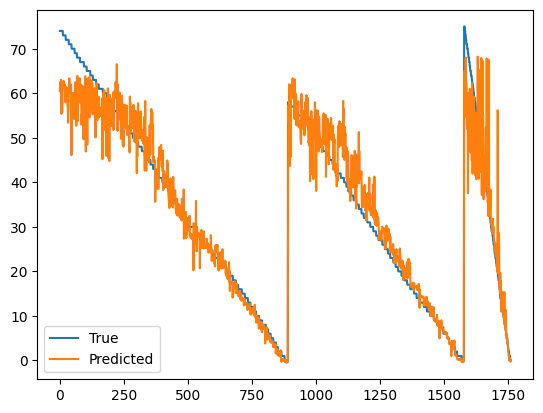

In [85]:
pd.DataFrame(
    {
        "True": y_test.flatten(),
        "Predicted": y_test_hat.flatten(),
        # 'Error': (y_test - y_test_hat).flatten()
    }
).plot()

In [64]:
y_test_hat

array([56.602947, 57.137516, 57.282192, 57.59192 , 57.360603, 57.373844,
       57.214363, 57.795135, 57.44352 , 57.619514, 57.56353 , 57.4153  ,
       57.583717, 58.180573, 58.438766, 57.935562, 58.13275 , 58.126244,
       57.99121 , 58.34401 , 58.257244, 58.246574, 57.983315, 58.130432,
       58.111313, 58.49023 , 59.063187, 59.23629 , 59.49264 , 59.44543 ,
       60.21923 , 59.533485, 59.138515, 59.683365, 59.827965, 60.147144,
       59.84926 , 60.158707, 60.45468 , 60.471992, 60.94095 , 60.6613  ,
       60.563194, 60.640114, 60.90257 , 60.681602, 60.98045 , 60.644684,
       60.753075, 61.206554, 61.27569 , 61.18634 , 60.985687, 61.079216,
       61.335266, 61.299137, 61.30755 , 61.233376, 61.83873 , 61.615112,
       61.419456, 61.49905 , 61.339703, 61.3058  , 61.457973, 61.50617 ,
       61.5142  , 61.593735, 61.75253 , 61.918175, 61.804817, 61.86947 ,
       61.893784, 62.05864 , 61.942078, 62.20143 , 62.209984, 62.13437 ,
       62.249897, 62.302475, 62.25367 , 62.209652, 

In [22]:
trainer = Trainer(
    model,
    optimizer,
    criterion=criterion,
    n_epochs=max_epochs,
)

trainer.fit(loaders)

Training model for 10 epochs...
[Epoch 1] train_loss = 278.97906, eval_loss = 25.85116, test_loss = 70.47343 [17.3s]
[Epoch 2] train_loss = 31.39655, eval_loss = 216.87270, test_loss = 398.83493 [19.5s]
[Epoch 3] train_loss = 28.49482, eval_loss = 23.42769, test_loss = 67.79177 [18.5s]
[Epoch 4] train_loss = 26.12981, eval_loss = 39.67807, test_loss = 99.57449 [18.2s]
[Epoch 5] train_loss = 26.71799, eval_loss = 79.57445, test_loss = 171.95001 [18.8s]
[Epoch 6] train_loss = 24.05432, eval_loss = 29.65828, test_loss = 100.43683 [18.9s]
[Epoch 7] train_loss = 24.43775, eval_loss = 130.31276, test_loss = 256.44363 [18.7s]
[Epoch 8] train_loss = 23.83715, eval_loss = 24.36523, test_loss = 69.89002 [18.4s]
[Epoch 9] train_loss = 22.37087, eval_loss = 34.85315, test_loss = 101.53964 [17.8s]
[Epoch 10] train_loss = 21.53308, eval_loss = 55.07464, test_loss = 165.22299 [18.1s]
Task done in 184s


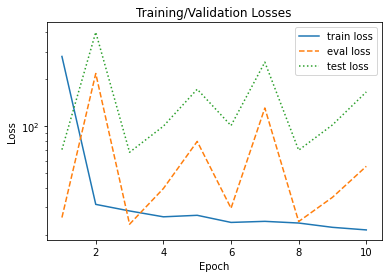

In [23]:
trainer.plot_losses()

### Evaluation on the test set

In [24]:
df_test = trainer.eval_rul_prediction(loaders[2])

Evaluating test RUL...
Model CNN saved in models/best_model_1102112705.pt loaded to cpu


100%|██████████| 613/613 [00:04<00:00, 133.13it/s]


<AxesSubplot:>

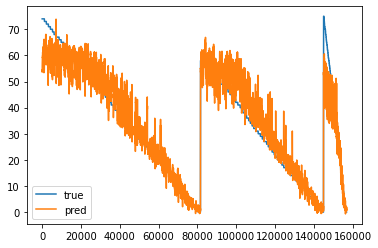

In [25]:
df_test.plot(y=["true", "pred"])

## Introduce NASA score

In [26]:
def nasa_score(y_pred, y_true):
    """
    Nasa score (in 1E5) as introduced in https://arxiv.org/abs/2003.00732
    """
    d = y_pred - y_true
    score = np.sum(np.exp(d[d >= 0] / 10) - 1) + np.sum(np.exp(-d[d < 0] / 13) - 1)
    return score / 1e5

In [27]:
nasa_score(df_test["pred"], df_test["true"])

0.97882640625

## Hyperparameter tuning

**Model parameters:** These are the parameters that are estimated by the model from the given data. For example the weights of a deep neural network. 

**Model hyperparameters:** These are the parameters that cannot be estimated by the model from the given data. These parameters are used to estimate the model parameters. For example, the learning rate in deep neural networks.

*Hyperparameter tuning* (or hyperparameter optimization) is the process of determining the right combination of hyperparameters that maximizes the model performance. It works by running multiple trials in a single training process. Each trial is a complete execution of your training application with values for your chosen hyperparameters, set within the limits you specify. This process once finished will give you the set of hyperparameter values that are best suited for the model to give optimal results.

There are many python libraries for hyperparameter tuning:
1. RayTune
2. Optuna
3. Hyperopt
4. sklearn
etc.

Here we will build a simple tuner using Optuna

In [28]:
!pip install -U optuna

There are several ways of hyperparameter tuning (all the above mentioned libraries apply several or all of those):

GridSearch : We create a discrete search space of hyperparameters to be tuned. This descrete search space grid is exhaustively searched for the best combination.

RandomSearch : We define distributions for each hyperparameter. Here the key difference is not all values are tested and values are selected at random. Since randomsearch does not test all hyperparameter values it does not necessarily return the best performing parameters, but it returns a good performing model in significantly shorter time

In [29]:
import optuna

This is an example of random search, Optuna Tune uses Bayesian optimization by default, however for this time we use the random search algorithm.


In [30]:
def evaluate_model(params, model):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(
        model.parameters(), lr=params["learning_rate"], weight_decay=1e-5
    )
    max_epochs = 10  # You can change this depending on the memory and time you have.
    trainer = Trainer(model, optimizer, criterion=criterion, n_epochs=max_epochs)
    trainer.fit(loaders)
    # using the EVAL set to pick the best performing model
    df_eval = trainer.eval_rul_prediction(loaders[1])
    pred_nasa_score = nasa_score(df_eval["pred"], df_eval["true"])
    return pred_nasa_score

In [31]:
def objective(trial):
    # We can add all the parameters that use for defining the model and trainer or even the dataset builder.

    # we define the parameter space.
    params = {
        "learning_rate": trial.suggest_float("lr", 1e-5, 1e-2, log=True),
        "n_layers": trial.suggest_int("nl", 2, 5),
    }
    # Build a model based on a sampled set from the parameter space
    model = CNN(
        in_channels=18,
        out_channels=1,
        n_ch=10,
        n_k=9,
        n_hidden=50,
        n_layers=params["n_layers"],
        dropout=0.0,
    )

    pred_nasa_score = evaluate_model(params, model)
    # Remember that we need to minimize the predicted nasa score.
    return pred_nasa_score

In [41]:
# define a study name, otherwise a random name will be generated
study_name = "hypertune_1"

In [32]:
n_trials = 2  # number of set of hyperparameters to train
# based on the output of the objective, we either maximize or minimize. If we returned accuracy, we would be maximize.
study = optuna.create_study(
    f"sqlite:///{folder}/study.db",
    study_name=study_name,
    direction="minimize",
    sampler=optuna.samplers.RandomSampler(seed=SEED),
)
study.optimize(objective, n_trials=n_trials)

C:\Users\mzhao\AppData\Local\Temp\ipykernel_25236\3579022078.py:3: FutureWarning: create_study(): Please give all values as keyword arguments. See https://github.com/optuna/optuna/issues/3324 for details.
  study = optuna.create_study(f'sqlite:///{folder}/study.db',
[I 2022-11-02 11:30:18,654] A new study created in RDB with name: no-name-1f2742fc-3ab8-4d5a-90da-b9c3e483310b


Training model for 10 epochs...
[Epoch 1] train_loss = 144.46999, eval_loss = 103.39127, test_loss = 215.84561 [24.8s]
[Epoch 2] train_loss = 26.64423, eval_loss = 1712.04871, test_loss = 2469.94287 [23.3s]
[Epoch 3] train_loss = 23.65117, eval_loss = 48.82558, test_loss = 165.31650 [23.5s]
[Epoch 4] train_loss = 21.90109, eval_loss = 125.32262, test_loss = 213.53322 [22.7s]
[Epoch 5] train_loss = 23.32699, eval_loss = 83.86282, test_loss = 247.31277 [21.3s]
[Epoch 6] train_loss = 22.21943, eval_loss = 219.65079, test_loss = 490.88101 [23.4s]
[Epoch 7] train_loss = 20.17332, eval_loss = 382.14114, test_loss = 588.91614 [26.0s]
[Epoch 8] train_loss = 20.14746, eval_loss = 142.19765, test_loss = 236.72356 [26.1s]
[Epoch 9] train_loss = 18.96409, eval_loss = 607.17786, test_loss = 986.21448 [26.9s]
[Epoch 10] train_loss = 18.15841, eval_loss = 58.35349, test_loss = 154.48259 [27.7s]
Task done in 245s
Evaluating test RUL...
Model CNN saved in models/best_model_1102113018.pt loaded to cpu


100%|██████████| 182/182 [00:02<00:00, 86.88it/s]
[I 2022-11-02 11:34:26,609] Trial 0 finished with value: 0.28935546875 and parameters: {'lr': 0.007917843011397504, 'nl': 5}. Best is trial 0 with value: 0.28935546875.


Training model for 10 epochs...
[Epoch 1] train_loss = 1393.62097, eval_loss = 1225.31165, test_loss = 1849.57593 [23.6s]
[Epoch 2] train_loss = 1136.30579, eval_loss = 1079.63074, test_loss = 1667.14282 [24.6s]
[Epoch 3] train_loss = 1006.41943, eval_loss = 942.34833, test_loss = 1495.14905 [32.1s]
[Epoch 4] train_loss = 841.95099, eval_loss = 757.74725, test_loss = 1246.80066 [30.4s]
[Epoch 5] train_loss = 655.38348, eval_loss = 579.95428, test_loss = 987.20880 [31.9s]
[Epoch 6] train_loss = 491.42447, eval_loss = 434.82877, test_loss = 759.49066 [22.1s]
[Epoch 7] train_loss = 351.12152, eval_loss = 265.46429, test_loss = 491.55829 [22.8s]
[Epoch 8] train_loss = 218.02869, eval_loss = 146.97926, test_loss = 301.06366 [23.8s]
[Epoch 9] train_loss = 128.23512, eval_loss = 128.98181, test_loss = 257.30441 [24.2s]
[Epoch 10] train_loss = 76.35649, eval_loss = 45.23661, test_loss = 105.38673 [23.7s]
Task done in 259s
Evaluating test RUL...
Model CNN saved in models/best_model_1102113426.p

100%|██████████| 182/182 [00:01<00:00, 96.67it/s] 
[I 2022-11-02 11:38:47,581] Trial 1 finished with value: 0.297670859375 and parameters: {'lr': 1.6606264014516748e-05, 'nl': 4}. Best is trial 0 with value: 0.28935546875.


In [39]:
# Load the study for resuming, comment out when reloading
# study = optuna.load_study(study_name=study_name, storage=f'sqlite:///{folder}/study.db')

### Visualizing impact of hyperparameters

In [34]:
# You can visualize the importance of hyperparameters
fig = optuna.visualization.plot_param_importances(study)
fig.show()

In [35]:
# Contour plot between two hyperparameters
fig = optuna.visualization.plot_contour(study, params=["lr", "nl"])
fig.show()

In [36]:
# you can get a dataframe of the hyperparamter results with:
hyper_df = study.trials_dataframe()
hyper_df

,number,value,datetime_start,datetime_complete,duration,params_lr,params_nl,state
0,0,0.289355,2022-11-02 11:30:18.679674,2022-11-02 11:34:26.574694,0 days 00:04:07.895020,0.007918,5,COMPLETE
1,1,0.297671,2022-11-02 11:34:26.616121,2022-11-02 11:38:47.554940,0 days 00:04:20.938819,0.000017,4,COMPLETE


### Get the best model parameter

In [37]:
# Get the est model parameter
best_trial = study.best_trial
for key, value in best_trial.params.items():
    print(f"{key}: {value:.5f}")

lr: 0.00792
nl: 5.00000


# Assignment 🚀
Units in the dataset  : 2, 5, 10, 16, 18, 20, 11, 14, 15

1. train a 1DCNN model with units 16, 18, 20

*   Describe the training steps and how the training is performed as in the model info sheet.


2. Evaluate the model performance with NASA score on: units **5, 11, 14**
*   How would you interpretet the result?

3. Tune the hyperparameters of the model for the best NASA score on the test set?
*   Which hyperparameter did you choose and why?

4. report the best performance on multiple evlauations on test set (at least 5) ?
